# Phase 1: Autoregressive models.

•Implement and train a simple MLP language model akin to Figure 1 in [2] that takes in the
three previous tokens (amino acids) and predicts the next, using a deep learning framework
such as PyTorch. The model architecture and hyperparameters are up to you, but clearly state
and justify your choices in the report.


•Implement and train a recurrent neural network (RNN) model or a causal decoder-only multi-
head attention Transformer model [3]. For the RNN choose between the vanilla RNN, Gated
Recurrent Unit (GRU) or Long Short-Term Memory (LSTM). Like the MLP, the specific model
design is up to you but needs to be explained and justified in the report.


•Evaluate and visualize the performance of these models by folding the generated sequences
with ESMFold [4] and presenting relevant metrics (code for evaluation will be provided).

---

## Importing the data

In [18]:
import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [19]:
#device = torch.device(
#    "mps" if torch.backends.mps.is_available() else "cpu"
#)
#print("Using:", device)

In [20]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

## nice little function 

In [35]:
from pathlib import Path
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from protgen.data import IGNORE_INDEX

def loss_and_accuracy(logits, targets):
    loss = F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        targets.reshape(-1),
        ignore_index=IGNORE_INDEX,
    )

    valid = targets.ne(IGNORE_INDEX)
    predictions = logits.argmax(dim=-1)
    accuracy = (
        predictions[valid] == targets[valid]
    ).float().mean()

    return loss, accuracy

## Defining the transformer

### Iniatiing embedings

For the embeddings we are intializing a trainable lookup table 

Num_embeddings is the vocab size 

Embeding dim, is an arbitary number we define, we define it as 128. But if our model is to weak, we can go back and increase it. 

It works by applying the embeding to each element in an input 

\<BOS>, A, C, \<EOS>, \<PAD>

x = torch.tensor([[1, 3, 4, 2, 0]])  # Shape: [1, 5]

embedded_x = token_embedding(x)     # Shape: [1, 5, 128]

In [21]:
token_embedding = nn.Embedding(
    num_embeddings=train_data.vocab_size,
    embedding_dim=128,
    padding_idx=train_data.vocab["<PAD>"], # PyTorch initializes that embedding row to zeros and excludes it from embedding-gradient updates
)

We now add positional embedings and combine them with our token embeding 

In [22]:
position_embedding = nn.Embedding(
    num_embeddings=train_data.max_length,
    embedding_dim=128,
)

# Run it on one batch to check the shapes
x, targets, family, lengths = next(iter(train_loader))


positions = torch.arange(x.size(1), device=x.device)
h = token_embedding(x) + position_embedding(positions)

print("Input shape:", x.shape)       # [32, 129]
print("Embedding shape:", h.shape)   # [32, 129, 128]

Input shape: torch.Size([32, 129])
Embedding shape: torch.Size([32, 129, 128])


### Building the casual mask 

For the Mask we want Query to be able to see the Key for its own position and the ones before it 

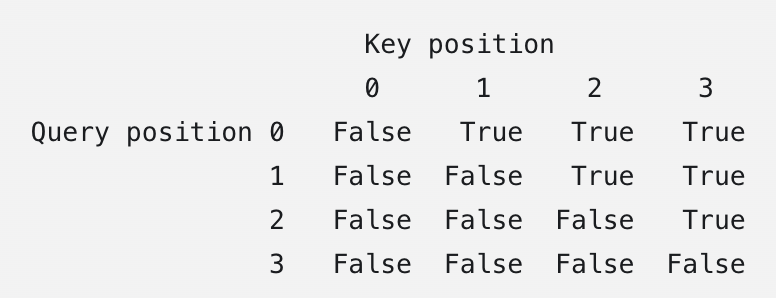

Torch ones, creates the matrix 129 x 129, and triu(ONES, diagonal=1) takes the matrix just created and sets points only over the diagonal to True. True in this case means that they are marked for blocking

In [23]:
T = x.size(1)
causal_mask = torch.triu( 
    torch.ones(T, T, dtype=torch.bool, device=x.device), 
    diagonal=1,
)

print(T)

129


### Building one transformer block

Here we introduce Multih head attention. Each head computes its own attention weights and their outputs are concatenated and projected back to 128 dimensions.

In [24]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model=128, n_heads=4, d_ff=512, dropout=0.1):
        super().__init__()

        # Normalization and creating heads
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=n_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.norm2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

        # Drops 10% of the residual connection
        self.residual_dropout = nn.Dropout(dropout)

    def forward(self, h, causal_mask, padding_mask):
        # Attention sublayer
        normalized = self.norm1(h)
        attended, _ = self.attention(
            normalized,
            normalized,
            normalized,
            attn_mask=causal_mask,
            key_padding_mask=padding_mask,
            need_weights=False,
        )
        h = h + self.residual_dropout(attended)

        # Feed-forward sublayer
        h = h + self.residual_dropout(
            self.feed_forward(self.norm2(h))
        )
        return h

### Stacking the blocks to create the transformer

In [25]:
class CausalProteinTransformer(nn.Module):
    def __init__(
        self,
        vocab_size=23,
        max_length=129,
        d_model=128,
        n_heads=4,
        n_layers=4,
        d_ff=512,
        dropout=0.1,
        pad_id=0,
    ):
        super().__init__()
        self.pad_id = pad_id

        self.token_embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=pad_id
        )
        self.position_embedding = nn.Embedding(max_length, d_model)
        self.embedding_dropout = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)
        ])

        self.final_norm = nn.LayerNorm(d_model)
        self.output = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        _, T = x.shape

        positions = torch.arange(T, device=x.device)
        h = self.token_embedding(x) + self.position_embedding(positions)
        h = self.embedding_dropout(h)

        causal_mask = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=x.device),
            diagonal=1,
        )
        padding_mask = x.eq(self.pad_id)

        for block in self.blocks:
            h = block(h, causal_mask, padding_mask)

        return self.output(self.final_norm(h))

In [26]:
# One batch test

model = CausalProteinTransformer(
    vocab_size=train_data.vocab_size,
    max_length=train_data.max_length,
    pad_id=train_data.vocab["<PAD>"],
)

x, targets, family, lengths = next(iter(train_loader))
logits = model(x)

print("Input:", x.shape)
print("Logits:", logits.shape)

loss = F.cross_entropy(
    logits.reshape(-1, train_data.vocab_size),
    targets.reshape(-1),
    ignore_index=-1,
)

print("Initial loss:", loss.item())

Input: torch.Size([32, 129])
Logits: torch.Size([32, 129, 23])
Initial loss: 3.2885310649871826


## Designing the training run

Training run is made with a frankenstein of the notebooks from week 3 and old machine learning projects:)

Had to rewrite it a bit because the dataloaders insist on importing to CPU and I don't wana change the supplied code.

### Setting up the model so its ready for training

In [43]:
# Reproducible initialization for a fresh training run.
torch.manual_seed(42)

model = CausalProteinTransformer(
    vocab_size=train_data.vocab_size,
    max_length=train_data.max_length,
    d_model=128,
    n_heads=4,
    n_layers=4,
    d_ff=512,
    dropout=0.1,
    pad_id=train_data.vocab["<PAD>"],
)

print("Fresh model initialized.")

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)
model = model.to(device)
print("Training on:", device)




Fresh model initialized.
Training on: mps


### Defineing our model paraemters and history params

In [44]:
batch_size_ = 128
num_updates = 1000

train_loader = DataLoader(
    train_data, batch_size=batch_size_, shuffle=True
)
val_loader = DataLoader(
    val_data, batch_size=batch_size_, shuffle=True
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=0.01,
)

train_losses, val_losses = [], []
train_accs, val_accs = [], []

history = {
    "train_loss": train_losses,
    "val_loss": val_losses,
    "train_acc": train_accs,
    "val_acc": val_accs,
}

checkpoint_path = Path("../results/checkpoints/transformer_best.pt")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
best_val_loss = float("inf")

### Training loop 

In [45]:
for update in range(num_updates):
    # Imports one batch of training 
    model.train()
    x, targets, _, _ = next(iter(train_loader))
    x = x.to(device)
    targets = targets.to(device)

    # Zero the gradients before running the backward pas so we dont have gradients from previous step
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    logits = model(x)
    train_loss, train_acc = loss_and_accuracy(logits, targets)
    train_loss.backward()

    # Clip gradients to avoid exploding gradients
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0,
        error_if_nonfinite=True,
    )

    # Update the model parameters based on the gradients computed during the backward pass
    optimizer.step()

    train_losses.append(train_loss.item())
    train_accs.append(train_acc.item())

    # Validation step
    model.eval()
    with torch.no_grad():
        x_val, targets_val, _, _ = next(iter(val_loader))
        x_val = x_val.to(device)
        targets_val = targets_val.to(device)

        val_logits = model(x_val)
        val_loss, val_acc = loss_and_accuracy(
            val_logits, targets_val
        )


    val_losses.append(val_loss.item())
    val_accs.append(val_acc.item())

    # Best checkpoint based on sampled validation-batch loss.
    if val_losses[-1] < best_val_loss:
        best_val_loss = val_losses[-1]
        torch.save(
            {
                name: tensor.detach().cpu()
                for name, tensor in model.state_dict().items()
            },
            checkpoint_path,
        )

    # Print training progress every 10 updates and the last update
    if update % 10 == 0 or update == num_updates - 1:
        print(
            f"Update {update:03d} | "
            f"Train loss: {train_losses[-1]:.3f} | "
            f"Val loss: {val_losses[-1]:.3f} | "
            f"Train acc: {train_accs[-1]:.3f} | "
            f"Val acc: {val_accs[-1]:.3f}",
            flush=True,
        )


Update 000 | Train loss: 3.318 | Val loss: 3.226 | Train acc: 0.046 | Val acc: 0.051
Update 010 | Train loss: 2.852 | Val loss: 2.799 | Train acc: 0.128 | Val acc: 0.152
Update 020 | Train loss: 2.772 | Val loss: 2.738 | Train acc: 0.146 | Val acc: 0.162
Update 030 | Train loss: 2.722 | Val loss: 2.659 | Train acc: 0.165 | Val acc: 0.194
Update 040 | Train loss: 2.670 | Val loss: 2.604 | Train acc: 0.186 | Val acc: 0.217
Update 050 | Train loss: 2.637 | Val loss: 2.569 | Train acc: 0.200 | Val acc: 0.228
Update 060 | Train loss: 2.652 | Val loss: 2.540 | Train acc: 0.200 | Val acc: 0.246
Update 070 | Train loss: 2.581 | Val loss: 2.502 | Train acc: 0.223 | Val acc: 0.259
Update 080 | Train loss: 2.593 | Val loss: 2.476 | Train acc: 0.216 | Val acc: 0.273
Update 090 | Train loss: 2.520 | Val loss: 2.444 | Train acc: 0.241 | Val acc: 0.292
Update 100 | Train loss: 2.493 | Val loss: 2.331 | Train acc: 0.255 | Val acc: 0.331
Update 110 | Train loss: 2.529 | Val loss: 2.378 | Train acc: 0.2

### EVAL of training 

Best sampled validation loss: 1.7284
Saved weights: ../results/checkpoints/transformer_best.pt


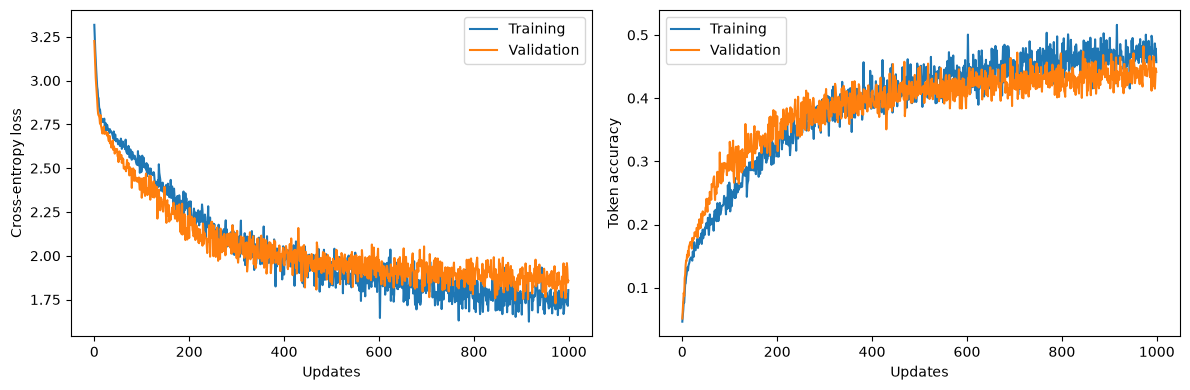

In [46]:
# Restore the best saved weights for evaluation.
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True,
    )
)
model.eval()

print(f"Best sampled validation loss: {best_val_loss:.4f}")
print(f"Saved weights: {checkpoint_path}")

updates = range(num_updates)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(updates, train_losses, label="Training")
axes[0].plot(updates, val_losses, label="Validation")
axes[0].set(xlabel="Updates", ylabel="Cross-entropy loss")
axes[0].legend()

axes[1].plot(updates, train_accs, label="Training")
axes[1].plot(updates, val_accs, label="Validation")
axes[1].set(xlabel="Updates", ylabel="Token accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

#### run the model on the test set

In [47]:
import math

test_loader = DataLoader(
    test_data,
    batch_size=batch_size_,
    shuffle=False,
)

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True,
    )
)
model.eval()

test_loss_sum = 0.0
test_correct = 0
test_token_count = 0

with torch.no_grad():
    for x, targets, _, _ in test_loader:
        x = x.to(device)
        targets = targets.to(device)

        logits = model(x)

        loss_sum = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            targets.reshape(-1),
            ignore_index=IGNORE_INDEX,
            reduction="sum",
        )

        valid = targets.ne(IGNORE_INDEX)
        predictions = logits.argmax(dim=-1)

        test_loss_sum += loss_sum.item()
        test_correct += (
            predictions[valid] == targets[valid]
        ).sum().item()
        test_token_count += valid.sum().item()

test_loss = test_loss_sum / test_token_count
test_accuracy = test_correct / test_token_count
test_perplexity = math.exp(test_loss)

print(f"Test loss:       {test_loss:.4f}")
print(f"Test accuracy:   {test_accuracy:.2%}")
print(f"Test perplexity: {test_perplexity:.2f}")

Test loss:       1.9031
Test accuracy:   43.29%
Test perplexity: 6.71
